In [75]:
!pip install xgboost lightgbm catboost

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
from tqdm import tqdm
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    balanced_accuracy_score,
    roc_auc_score,roc_curve,
    precision_recall_curve,average_precision_score
)
# Classification models
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier

from sklearn.naive_bayes import GaussianNB

from sklearn.ensemble import (
    RandomForestClassifier,
    ExtraTreesClassifier,
    AdaBoostClassifier,
    GradientBoostingClassifier,
    HistGradientBoostingClassifier,
    VotingClassifier,
    StackingClassifier
)

from xgboost import XGBClassifier
from catboost import CatBoostClassifier
from lightgbm import LGBMClassifier


| Column Name | Arabic Meaning | Data Type | Description |
|---|---|---|---|
| `age` | العمر | Numerical | Age of the client in years |
| `job` | الوظيفة | Categorical | Type of job |
| `marital` | الحالة الاجتماعية | Categorical | Marital status: single, married, divorced |
| `education` | المستوى التعليمي | Categorical | Education level |
| `default` | التعثر الائتماني | Categorical | Whether the client has credit in default |
| `balance` | الرصيد البنكي | Numerical | Client's bank balance |
| `housing` | قرض سكني | Categorical | Whether the client has a housing loan |
| `loan` | قرض شخصي | Categorical | Whether the client has a personal loan |
| `contact` | وسيلة التواصل | Categorical | Communication type |
| `day` | يوم التواصل | Numerical (Discrete) | Day of the month of the last contact |
| `month` | شهر التواصل | Categorical | Month of the last contact |
| `duration` | مدة المكالمة | Numerical | Duration of the last contact in seconds |
| `campaign` | عدد محاولات التواصل | Numerical (Discrete) | Number of contacts during the current campaign |
| `pdays` | الأيام منذ التواصل السابق | Numerical (Special) | Days since the client was last contacted in a previous campaign; `-1` usually means no previous contact |
| `previous` | مرات التواصل السابقة | Numerical (Discrete) | Number of contacts before the current campaign |
| `poutcome` | نتيجة الحملة السابقة | Categorical | Outcome of the previous marketing campaign |
| `deposit` | الاشتراك في الوديعة | Categorical (Target) | Whether the client subscribed to a term deposit |



In [76]:
df = pd.read_csv('/content/bank.csv')
df

,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,deposit
0,59,admin.,married,secondary,no,2343.0,yes,no,unknown,5.0,may,1042.0,1.0,-1.0,0.0,unknown,yes
1,56,admin.,married,secondary,no,45.0,no,no,unknown,5.0,may,1467.0,1.0,-1.0,0.0,unknown,yes
2,41,technician,married,secondary,no,1270.0,yes,no,unknown,5.0,may,1389.0,1.0,-1.0,0.0,unknown,yes
3,54,admin.,married,tertiary,no,184.0,no,no,unknown,5.0,may,673.0,2.0,-1.0,0.0,unknown,yes
4,42,management,single,tertiary,no,0.0,yes,yes,unknown,5.0,may,562.0,2.0,-1.0,0.0,unknown,yes
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8907,33,blue-collar,single,primary,no,1.0,yes,no,cellular,20.0,apr,257.0,1.0,-1.0,0.0,unknown,no
8908,39,services,married,secondary,no,733.0,no,no,unknown,16.0,jun,83.0,4.0,-1.0,0.0,unknown,no
8909,32,technician,single,secondary,no,29.0,no,no,cellular,19.0,aug,156.0,2.0,-1.0,0.0,unknown,no
8910,43,technician,married,secondary,no,0.0,no,yes,cellular,8.0,may,9.0,2.0,172.0,5.0,failure,no


In [77]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8912 entries, 0 to 8911
Data columns (total 17 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   age        8912 non-null   int64  
 1   job        8905 non-null   object 
 2   marital    8743 non-null   object 
 3   education  8885 non-null   object 
 4   default    8908 non-null   object 
 5   balance    8899 non-null   float64
 6   housing    8899 non-null   object 
 7   loan       8882 non-null   object 
 8   contact    8881 non-null   object 
 9   day        8893 non-null   float64
 10  month      8884 non-null   object 
 11  duration   8905 non-null   float64
 12  campaign   8904 non-null   float64
 13  pdays      8767 non-null   float64
 14  previous   8909 non-null   float64
 15  poutcome   8912 non-null   object 
 16  deposit    8903 non-null   object 
dtypes: float64(6), int64(1), object(10)
memory usage: 1.2+ MB


In [78]:
df.describe()

,age,balance,day,duration,campaign,pdays,previous
count,8912.000000,8899.000000,8893.000000,8905.000000,8904.000000,8767.000000,8909.000000
mean,41.257855,1539.680638,15.684921,374.953734,2.512579,52.456941,0.834325
std,11.840567,3297.446702,8.406729,351.283501,2.772366,109.094161,2.304733
min,18.000000,-3058.000000,1.000000,3.000000,1.000000,-1.000000,0.000000
25%,32.000000,121.500000,8.000000,139.000000,1.000000,-1.000000,0.000000
50%,39.000000,553.000000,15.000000,256.000000,2.000000,-1.000000,0.000000
75%,49.000000,1726.000000,22.000000,501.000000,3.000000,64.000000,1.000000
max,95.000000,81204.000000,31.000000,3284.000000,63.000000,842.000000,58.000000


In [79]:
df.isnull().sum()

,0
age,0
job,7
marital,169
education,27
default,4
balance,13
housing,13
loan,30
contact,31
day,19


In [80]:
df.duplicated().sum()

np.int64(0)

In [81]:
for col in df.columns:
    print(f"Unique values in '{col}':")
    print(df[col].unique())
    print('*' * 50)

Unique values in 'age':
[59 56 41 54 42 60 37 28 38 30 29 31 35 32 49 43 26 40 33 23 48 36 52 53
 39 51 44 24 50 34 47 27 45 25 46 58 55 57 61 68 75 69 66 22 72 67 71 65
 85 62 21 70 76 83 77 19 63 20 74 78 73 95 64 79 82 18 86 84 87 92 80 81
 90 93 88 89]
**************************************************
Unique values in 'job':
['admin.' 'technician' 'management' 'retired' 'services' 'blue-collar'
 'unemployed' 'entrepreneur' 'housemaid' 'unknown' 'self-employed'
 'student' nan]
**************************************************
Unique values in 'marital':
['married' 'single' 'divorced' nan]
**************************************************
Unique values in 'education':
['secondary' 'tertiary' 'primary' 'unknown' nan]
**************************************************
Unique values in 'default':
['no' 'yes' nan]
**************************************************
Unique values in 'balance':
[2343.   45. 1270. ... 2593. -134.  917.]
**************************************************
U

In [82]:
cols = ['job','marital','education','default','housing','loan','contact','month']
from sklearn.impute import SimpleImputer
for i in cols:
  imputer = SimpleImputer(strategy='most_frequent')
  df[[i]] = imputer.fit_transform(df[[i]])


In [83]:
df.isnull().sum()

,0
age,0
job,0
marital,0
education,0
default,0
balance,13
housing,0
loan,0
contact,0
day,19


In [84]:
ncols = ['balance','day','duration','campaign','pdays','previous']

for i in ncols:
  imputer = SimpleImputer(strategy='median')
  df[[i]] = imputer.fit_transform(df[[i]])

In [85]:
df.dropna(inplace=True)

In [86]:
df.shape

(8903, 17)

In [87]:
df.reset_index(drop=True,inplace=True)

<Axes: xlabel='age', ylabel='Density'>

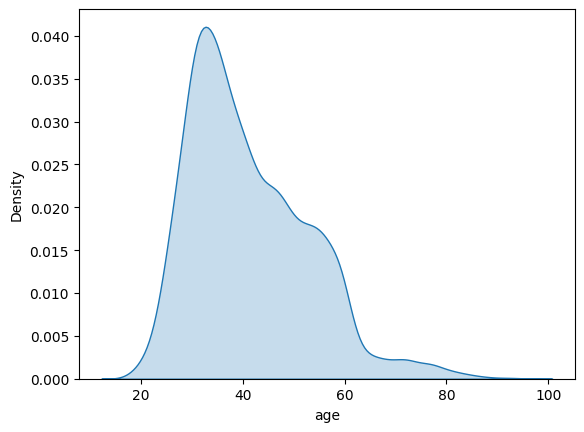

In [88]:
sns.kdeplot(data=df,x='age',fill=True)

In [89]:
fig = px.histogram(df, x='deposit', title='Count of Deposits')
fig.show()

fig = px.histogram(df, x='job', title='Count of Jobs')
fig.show()

fig = px.histogram(df, x='marital', title='Count of Marital Status')
fig.show()

fig = px.histogram(df, x='education', title='Count of Education Levels')
fig.show()

fig = px.histogram(df, x='poutcome', title='Count of Previous Marketing Campaigns')
fig.show()



In [90]:
px.violin(df,x='age',y='deposit',title='Age vs Deposit')

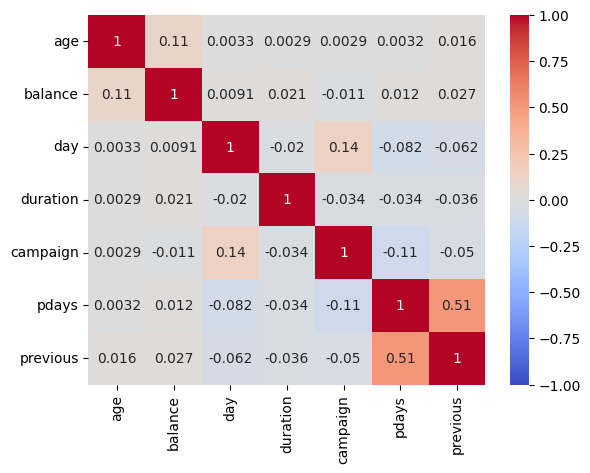

In [91]:
corr = df.select_dtypes(
    include="number"
).corr()

sns.heatmap(
    corr, annot=True,
    cmap="coolwarm", vmin=-1, vmax=1
)
plt.show()

In [92]:
px.box(df,x='age',y='deposit',title='Age vs Balance')

In [93]:
for i in df.select_dtypes('object').columns:
    print(f"Unique values in '{i}':", df[i].nunique())
    print('*' * 50)

Unique values in 'job': 12
**************************************************
Unique values in 'marital': 3
**************************************************
Unique values in 'education': 4
**************************************************
Unique values in 'default': 2
**************************************************
Unique values in 'housing': 2
**************************************************
Unique values in 'loan': 2
**************************************************
Unique values in 'contact': 3
**************************************************
Unique values in 'month': 12
**************************************************
Unique values in 'poutcome': 4
**************************************************
Unique values in 'deposit': 2
**************************************************


In [94]:
ocols=['job','marital','education','default','housing','loan','contact','month','poutcome']
from sklearn.preprocessing import OneHotEncoder

ohe = OneHotEncoder(handle_unknown='ignore')
for i in ocols:
  ohe_encoded = ohe.fit_transform(df[[i]]).toarray()
  ohe_df = pd.DataFrame(ohe_encoded, columns=ohe.get_feature_names_out([i]),index=df.index)
  df = pd.concat([df, ohe_df],axis=1)
  df.drop(i,axis=1,inplace=True)

In [95]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8903 entries, 0 to 8902
Data columns (total 52 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   age                  8903 non-null   int64  
 1   balance              8903 non-null   float64
 2   day                  8903 non-null   float64
 3   duration             8903 non-null   float64
 4   campaign             8903 non-null   float64
 5   pdays                8903 non-null   float64
 6   previous             8903 non-null   float64
 7   deposit              8903 non-null   object 
 8   job_admin.           8903 non-null   float64
 9   job_blue-collar      8903 non-null   float64
 10  job_entrepreneur     8903 non-null   float64
 11  job_housemaid        8903 non-null   float64
 12  job_management       8903 non-null   float64
 13  job_retired          8903 non-null   float64
 14  job_self-employed    8903 non-null   float64
 15  job_services         8903 non-null   f

In [96]:
x = df.drop('deposit',axis=1)
y = df['deposit']


In [97]:
from sklearn.model_selection import train_test_split

x_train,x_test,y_train,y_test = train_test_split(x,y,test_size=0.2,random_state=100,stratify=None)

In [98]:
numcols = ['age','balance','day','duration','campaign','pdays','previous']

In [99]:
from sklearn.preprocessing import StandardScaler
sc = StandardScaler()

x_train[numcols] = sc.fit_transform(x_train[numcols])
x_test[numcols] = sc.transform(x_test[numcols])

In [100]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score,f1_score,precision_score,recall_score,confusion_matrix,classification_report

results = []

model = LogisticRegression()
model.fit(x_train,y_train)
y_pred = model.predict(x_test)

results.append({
    'Method':'Normal Data',
    'Accuracy' : accuracy_score(y_test,y_pred)
})

In [101]:
print(classification_report(y_test,y_pred))

              precision    recall  f1-score   support

          no       0.83      0.85      0.84       948
         yes       0.82      0.80      0.81       833

    accuracy                           0.83      1781
   macro avg       0.83      0.83      0.83      1781
weighted avg       0.83      0.83      0.83      1781



In [102]:
!pip install imblearn
from imblearn.over_sampling import SMOTE
smote = SMOTE()
x_train_smote,y_train_smote = smote.fit_resample(x_train,y_train)
print('x_train_smote = ',x_train_smote.shape)
print('y_train_smote = ',y_train_smote.shape)

x_train_smote =  (7450, 51)
y_train_smote =  (7450,)


In [103]:
y_train_smote.value_counts()

,count
deposit,
yes,3725
no,3725


In [104]:
model = LogisticRegression(class_weight='balanced')
model.fit(x_train,y_train)
y_pred = model.predict(x_test)

results.append({
    'Method':'Class Weight Balancing',
    'Accuracy' : accuracy_score(y_test,y_pred)
})

In [105]:
model = LogisticRegression(class_weight={'yes':1,'no':5})
model.fit(x_train,y_train)
y_pred = model.predict(x_test)

results.append({
    'Method':'Class Weight Balancing',
    'Accuracy' : accuracy_score(y_test,y_pred)
})


In [106]:
results_df = pd.DataFrame(results).set_index('Method')
results_df

,Accuracy
Method,
Normal Data,0.827625
Class Weight Balancing,0.822572
Class Weight Balancing,0.688377


In [107]:
from sklearn.neighbors import KNeighborsClassifier

results = []
model = KNeighborsClassifier(n_neighbors=5, metric='minkowski', p=1)

model.fit(x_train, y_train)

y_pred_train = model.predict(x_train)
y_pred_test = model.predict(x_test)

Acc_train = accuracy_score(y_train, y_pred_train)
Acc_test = accuracy_score(y_test, y_pred_test)

results.append({
    'Method':'KNN',
    'Accuracy' : Acc_test
})

In [108]:
print('Accuracy train :',Acc_train,'Accuracy test :',Acc_test)


Accuracy train : 0.8600112327997753 Accuracy test : 0.8017967434025828


In [109]:
print(classification_report(y_test,y_pred))

              precision    recall  f1-score   support

          no       0.64      0.95      0.77       948
         yes       0.88      0.39      0.54       833

    accuracy                           0.69      1781
   macro avg       0.76      0.67      0.65      1781
weighted avg       0.75      0.69      0.66      1781



In [110]:
from sklearn.naive_bayes import GaussianNB

In [111]:
model.fit(x_train,y_train)

y_pred_train = model.predict(x_train)
y_pred_test = model.predict(x_test)

Acc_train = accuracy_score(y_train, y_pred_train)
Acc_test = accuracy_score(y_test, y_pred_test)

print(classification_report(y_test,y_pred))


              precision    recall  f1-score   support

          no       0.64      0.95      0.77       948
         yes       0.88      0.39      0.54       833

    accuracy                           0.69      1781
   macro avg       0.76      0.67      0.65      1781
weighted avg       0.75      0.69      0.66      1781



In [112]:
from sklearn.svm import SVC

model = SVC(C=0.1, kernel='linear',gamma="auto")
model.fit(x_train,y_train)

SVC(C=0.1, gamma='auto', kernel='linear')

In [113]:
y_pred = model.predict(x_test)

In [114]:
print(accuracy_score(y_test,y_pred))
print(classification_report(y_test,y_pred))

0.8276249298147108
              precision    recall  f1-score   support

          no       0.84      0.83      0.84       948
         yes       0.81      0.82      0.82       833

    accuracy                           0.83      1781
   macro avg       0.83      0.83      0.83      1781
weighted avg       0.83      0.83      0.83      1781



In [115]:
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV, cross_val_score, StratifiedKFold
grid_params = {
    'C': [0.1, 1, 10, 100],
    'kernel': ['linear', 'rbf', 'poly'],
    'gamma': ['auto', 'scale']
}

In [116]:
# grid = GridSearchCV(estimator=SVC(), param_grid=grid_params, cv=5, scoring='accuracy')

# grid.fit(x_train, y_train)

In [117]:
# print(grid.best_params_)
# print(grid.best_score_)


In [118]:
# best_model = grid.best_estimator_


In [119]:
# y_pred = best_model.predict(x_test)

# print(accuracy_score(y_test, y_pred))
# print(classification_report(y_test, y_pred))

In [120]:
# random_param = {
#     'C': [0.1, 1, 10, 100],
#     'kernel': ['linear', 'rbf', 'poly'],
#     'gamma': ['auto', 'scale']
# }

In [121]:
# random = RandomizedSearchCV(estimator=SVC(), param_distributions=random_param, cv=5, scoring='accuracy')

# random.fit(x_train, y_train)

In [122]:
# print(random.best_params_)
# print(random.best_score_)

In [123]:
# kfold = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# score = cross_val_score(best_model, x_train, y_train, cv=kfold, scoring='accuracy')

# print(score)
# print(score.mean())

In [124]:
# import gradio as gr

In [125]:
# def predict(glucose, bmi, blood_pressure, age, insulin, diabetes_pedigree):
#     X_new = pd.DataFrame([[
#         glucose, bmi, blood_pressure,
#         age, insulin, diabetes_pedigree
#     ]], columns=[
#         'glucose', 'bmi', 'blood_pressure',
#         'age', 'insulin', 'diabetes_pedigree'
#     ])

#     X_new = imputer.transform(X_new)
#     X_new = scaler.transform(X_new)

#     prediction = best_model.predict(X_new)[0]

#     return "Diabetic" if prediction == 1 else "Non-Diabetic"

# demo = gr.Interface(
#     fn=predict,
#     inputs=[
#         gr.Number(label="Glucose"),
#         gr.Number(label="BMI"),
#         gr.Number(label="Blood Pressure"),
#         gr.Number(label="Age"),
#         gr.Number(label="Insulin"),
#         gr.Number(label="Diabetes Pedigree")
#     ],
#     outputs=gr.Textbox(label="Prediction"),
#     title="Diabetes Risk Prediction",
#     description="Enter patient data to predict the diabetes class."
# )

# demo.launch(share=True)

In [126]:
from sklearn.tree import DecisionTreeClassifier,plot_tree


In [127]:
model = DecisionTreeClassifier(

        # Split quality measure
        # "gini"      → Gini impurity (default, fast)
        # "entropy"   → Information gain (ID3 style)
        # "log_loss"  → Similar to entropy but probabilistic
        criterion='gini',

        # Controls randomness for reproducibility
        random_state=100,

        # ================= Pre-Pruning =================

        # Maximum depth of the tree
        # None → grow until pure or min_samples reached
        max_depth=10, # None for unlimited depth

        # Minimum samples required to split a node
        min_samples_split=10,

        # Minimum samples required at leaf node
        min_samples_leaf=5,

        # Minimum impurity reduction required to split
        min_impurity_decrease=0.01,

        # ================= Post-Pruning =================

        # Cost complexity pruning parameter
        # Higher value → more pruning
        ccp_alpha=0.01
    )



In [128]:
from sklearn.metrics import accuracy_score

In [129]:
# Train model
model.fit(x_train, y_train)

# Predictions
y_pred_train = model.predict(x_train)
y_pred_test  = model.predict(x_test)

# ================= Metrics =================
Acc_Train = accuracy_score(y_train, y_pred_train)
Acc_Test  = accuracy_score(y_test, y_pred_test)

print(
    Acc_Train,
    Acc_Test,
)

0.7760460544790789 0.7478944413250983


Decision Tree - Plotting the tree


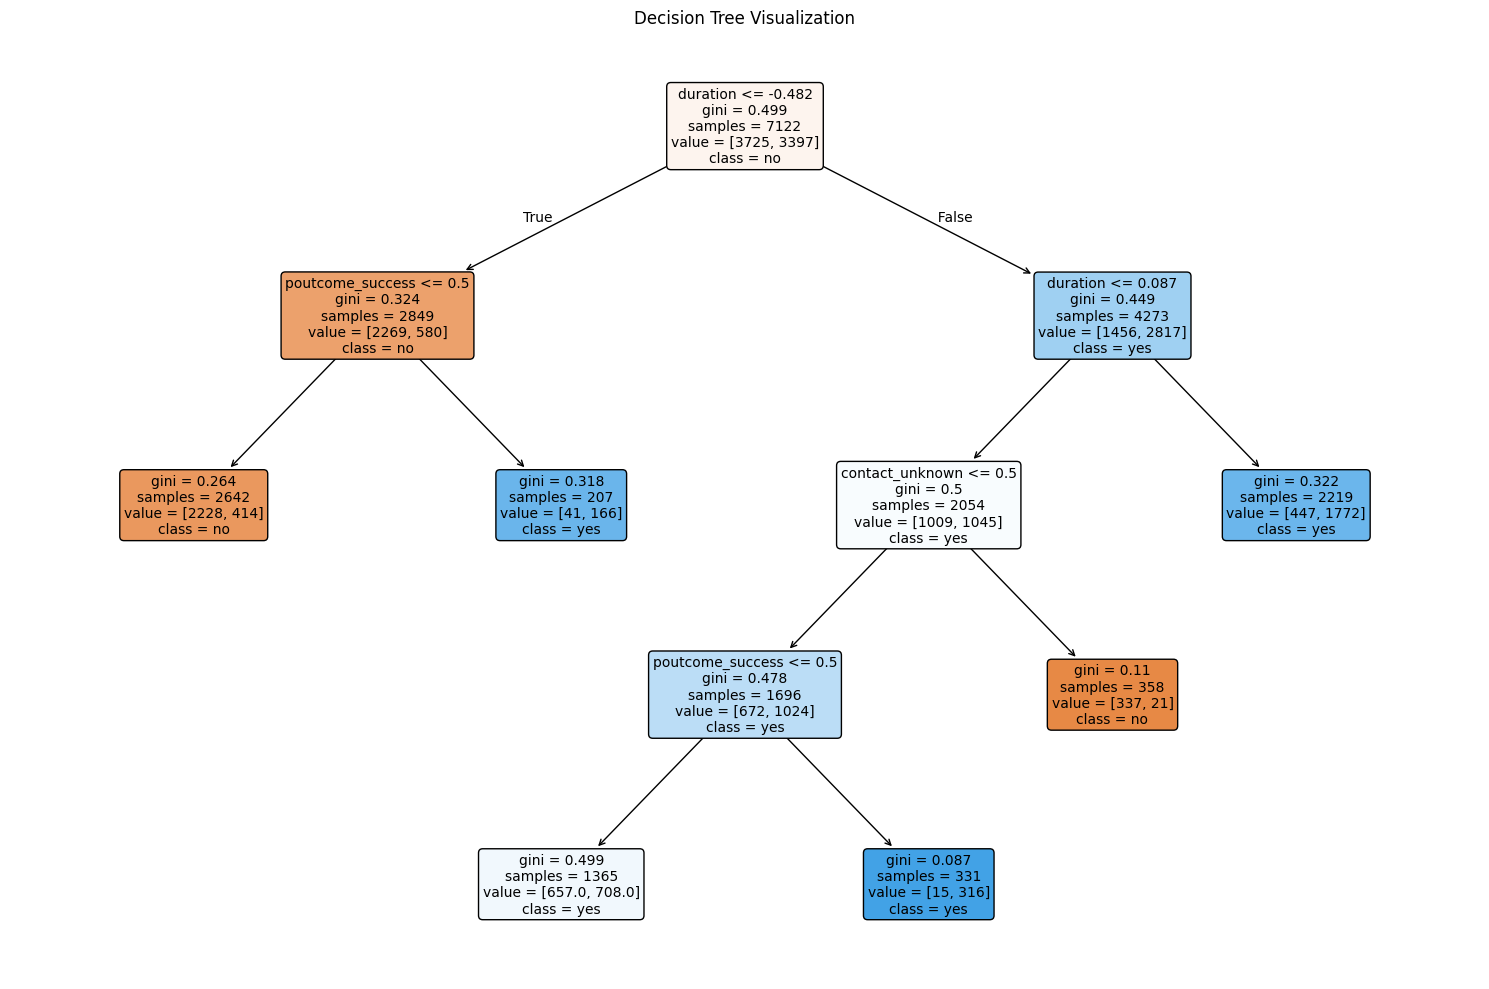

In [130]:
print("Decision Tree - Plotting the tree")

plt.figure(figsize=(15, 10))
plot_tree(
    model,
    feature_names=x.columns.tolist(),
    class_names=[str(c) for c in model.classes_],
    filled=True,
    rounded=True,
    fontsize=10
)
plt.title("Decision Tree Visualization")
plt.tight_layout()
plt.show()

In [131]:
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV, cross_val_score, StratifiedKFold
grid_params = {
    'criterion': ['gini', 'entropy'],
    'max_depth': [3, 5, 10, None],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 5]
}

In [132]:
grid = GridSearchCV(estimator=DecisionTreeClassifier(), param_grid=grid_params, cv=5, scoring='accuracy')

grid.fit(x_train, y_train)

GridSearchCV(cv=5, estimator=DecisionTreeClassifier(),
             param_grid={'criterion': ['gini', 'entropy'],
                         'max_depth': [3, 5, 10, None],
                         'min_samples_leaf': [1, 2, 5],
                         'min_samples_split': [2, 5, 10]},
             scoring='accuracy')

In [133]:
print(grid.best_params_)
print(grid.best_score_)


{'criterion': 'gini', 'max_depth': 10, 'min_samples_leaf': 1, 'min_samples_split': 10}
0.8223825152769564


In [134]:
best_model = grid.best_estimator_


In [135]:
y_pred = best_model.predict(x_test)

print(accuracy_score(y_test, y_pred))
print(classification_report(y_test, y_pred))

0.8208871420550252
              precision    recall  f1-score   support

          no       0.86      0.79      0.82       948
         yes       0.78      0.86      0.82       833

    accuracy                           0.82      1781
   macro avg       0.82      0.82      0.82      1781
weighted avg       0.82      0.82      0.82      1781



In [136]:
from sklearn.tree import DecisionTreeClassifier

rf = DecisionTreeClassifier( random_state=42)
rf.fit(x_train, y_train)

# Get top 10 important features
importances = pd.Series(rf.feature_importances_,index=x.columns)

importances = importances.sort_values(ascending=False)

selected_columns = importances.sort_values(ascending=False).index[:5]
print("Random Forest Selected Features:",selected_columns.tolist())
selected_features = importances.nlargest(5)
print("Random Forest Selected Features:", selected_features.tolist())

Random Forest Selected Features: ['duration', 'day', 'poutcome_success', 'balance', 'contact_unknown']
Random Forest Selected Features: [0.3361778821536217, 0.0791357109047398, 0.07660711875526162, 0.07536486038321599, 0.06340385409783823]


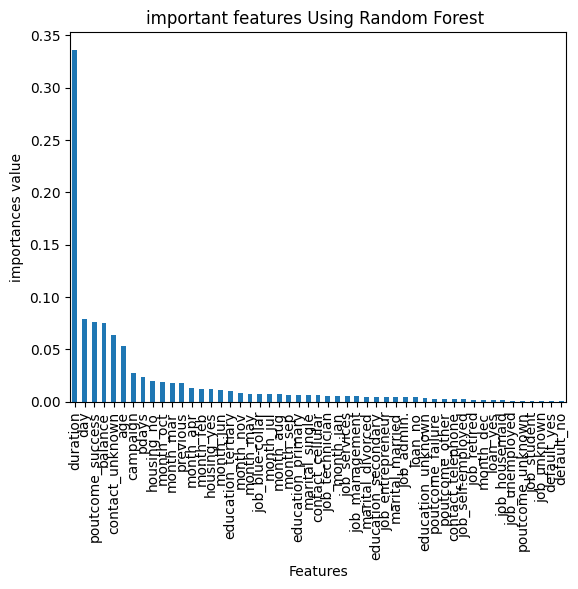

In [137]:
importances.plot(kind='bar')
plt.title("important features Using Random Forest ")
plt.xlabel("Features")
plt.ylabel("importances value")
plt.show()

In [138]:
models = {

    # Linear
    "Logistic Regression": LogisticRegression(max_iter=2000, random_state=1),

    # Distance-based
    "KNN": KNeighborsClassifier(n_neighbors=5),

    # SVM
    "SVC": SVC(probability=True, random_state=1),

    # Tree
    "Decision Tree": DecisionTreeClassifier(random_state=1),

    # Naive Bayes
    "Naive Bayes": GaussianNB(),

    # Bagging Based
    "Random Forest": RandomForestClassifier(n_estimators=100, random_state=1),
    "Extra Trees": ExtraTreesClassifier(n_estimators=100, random_state=1),

    # Boosting
    "AdaBoost": AdaBoostClassifier(random_state=1),
    "Gradient Boosting": GradientBoostingClassifier(random_state=1),
    "Hist Gradient Boosting": HistGradientBoostingClassifier(random_state=1),

    # External Boosting Libraries
    "XGBoost": XGBClassifier(eval_metric='logloss', random_state=1, use_label_encoder=False),
    "CatBoost": CatBoostClassifier(verbose=0, random_state=1),
    "LightGBM": LGBMClassifier(random_state=1)
}

  0%|          | 0/13 [00:00<?, ?it/s]


Confusion Matrix:
 [[804 144]
 [163 670]]


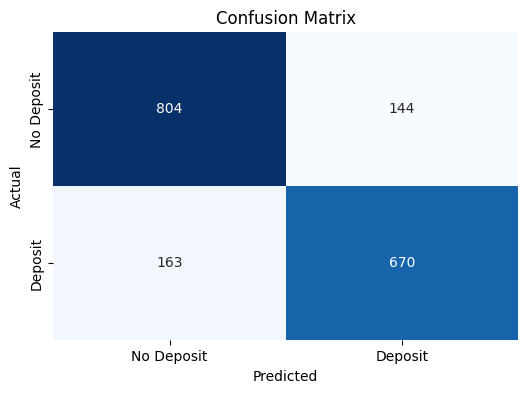


Classification Report:

              precision    recall  f1-score   support

  No Deposit       0.83      0.85      0.84       948
     Deposit       0.82      0.80      0.81       833

    accuracy                           0.83      1781
   macro avg       0.83      0.83      0.83      1781
weighted avg       0.83      0.83      0.83      1781

ROC-AUC: 0.8925139676123615


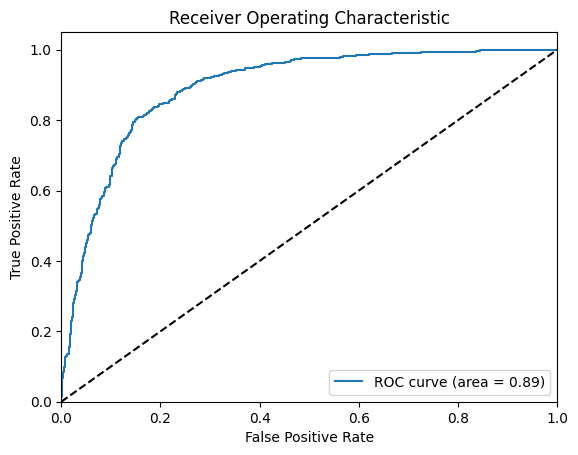

PR AUC: 0.8557819030417645


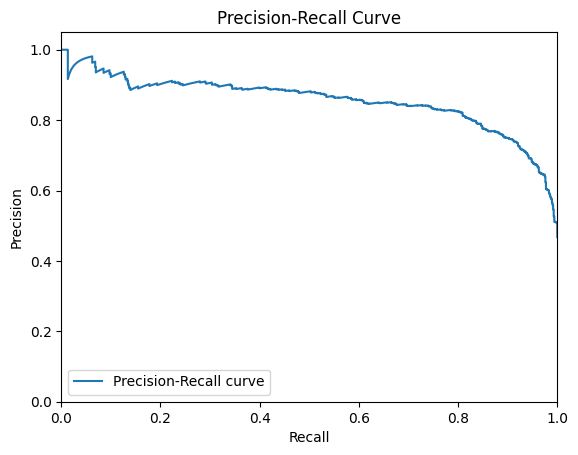

  8%|▊         | 1/13 [00:00<00:11,  1.05it/s]


Confusion Matrix:
 [[794 154]
 [200 633]]


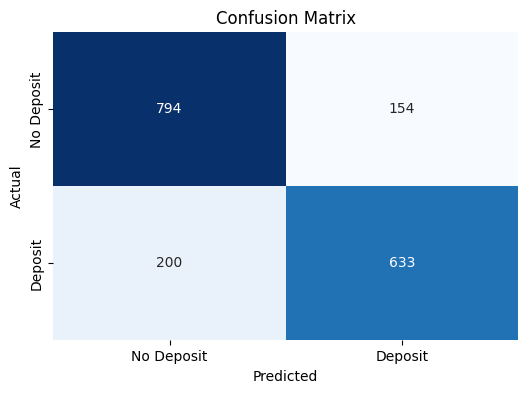


Classification Report:

              precision    recall  f1-score   support

  No Deposit       0.80      0.84      0.82       948
     Deposit       0.80      0.76      0.78       833

    accuracy                           0.80      1781
   macro avg       0.80      0.80      0.80      1781
weighted avg       0.80      0.80      0.80      1781

ROC-AUC: 0.8670379544222753


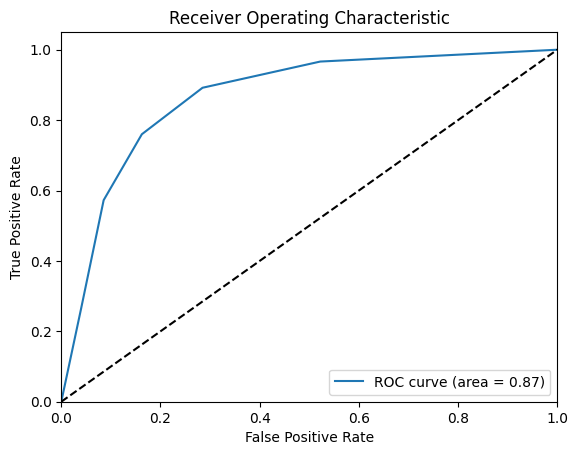

PR AUC: 0.7983882560017901


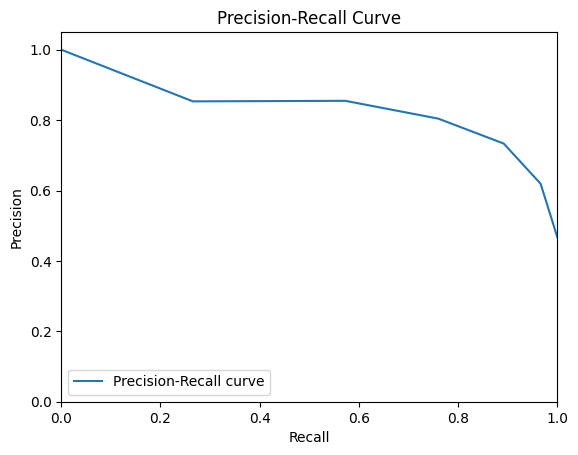

 15%|█▌        | 2/13 [00:05<00:32,  2.93s/it]


Confusion Matrix:
 [[765 183]
 [ 97 736]]


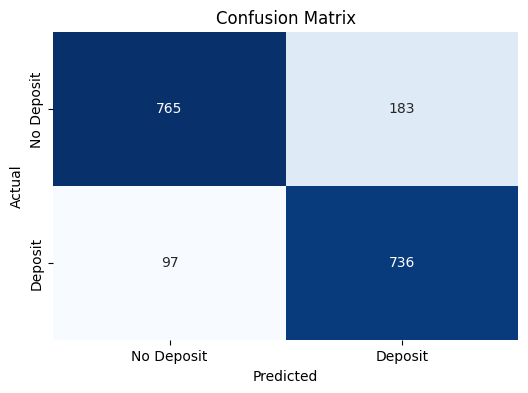


Classification Report:

              precision    recall  f1-score   support

  No Deposit       0.89      0.81      0.85       948
     Deposit       0.80      0.88      0.84       833

    accuracy                           0.84      1781
   macro avg       0.84      0.85      0.84      1781
weighted avg       0.85      0.84      0.84      1781

ROC-AUC: 0.9106541350717503


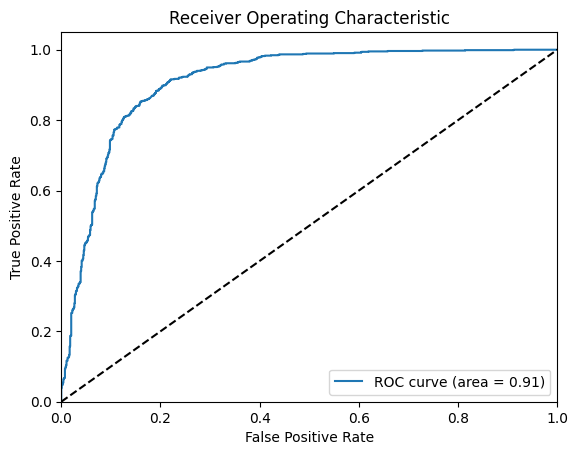

PR AUC: 0.8685083644760335


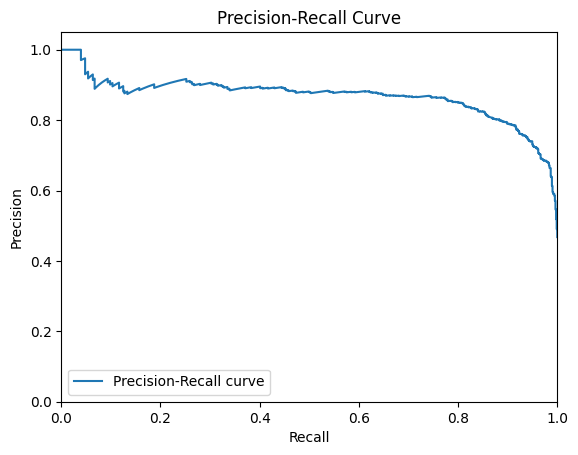

 23%|██▎       | 3/13 [00:31<02:17, 13.71s/it]


Confusion Matrix:
 [[725 223]
 [203 630]]


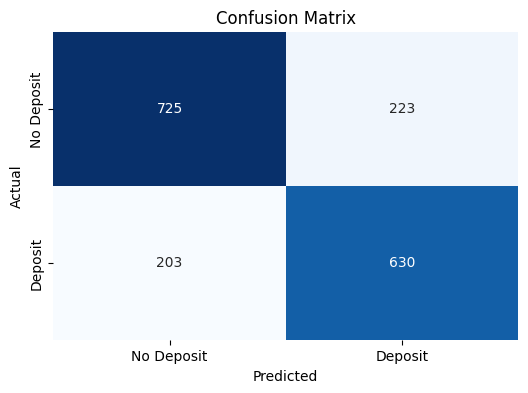


Classification Report:

              precision    recall  f1-score   support

  No Deposit       0.78      0.76      0.77       948
     Deposit       0.74      0.76      0.75       833

    accuracy                           0.76      1781
   macro avg       0.76      0.76      0.76      1781
weighted avg       0.76      0.76      0.76      1781

ROC-AUC: 0.7605352267489274


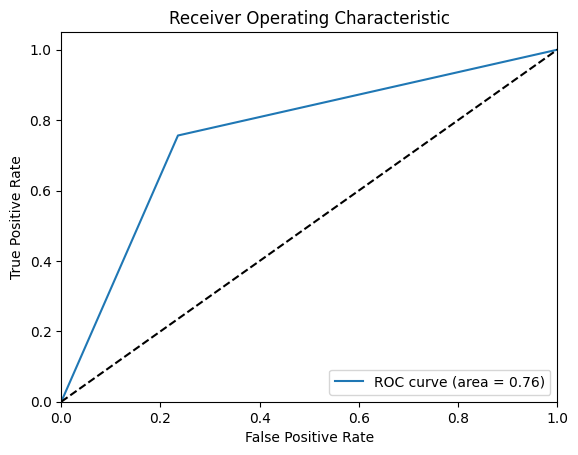

PR AUC: 0.6725630763484685


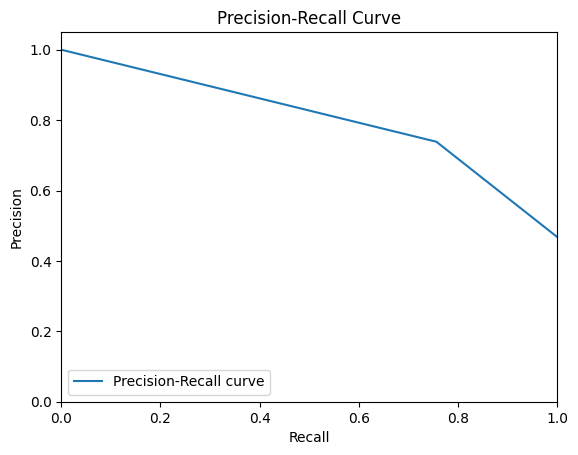

 31%|███       | 4/13 [00:32<01:16,  8.51s/it]


Confusion Matrix:
 [[800 148]
 [392 441]]


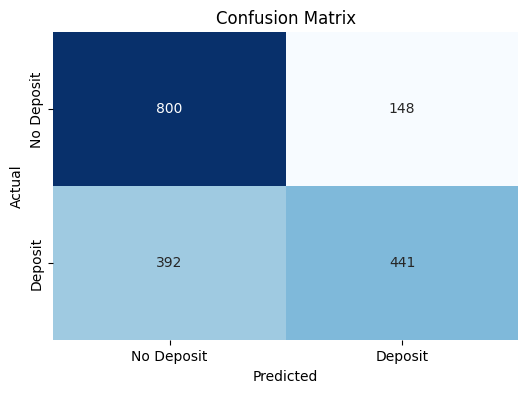


Classification Report:

              precision    recall  f1-score   support

  No Deposit       0.67      0.84      0.75       948
     Deposit       0.75      0.53      0.62       833

    accuracy                           0.70      1781
   macro avg       0.71      0.69      0.68      1781
weighted avg       0.71      0.70      0.69      1781

ROC-AUC: 0.7738722071106923


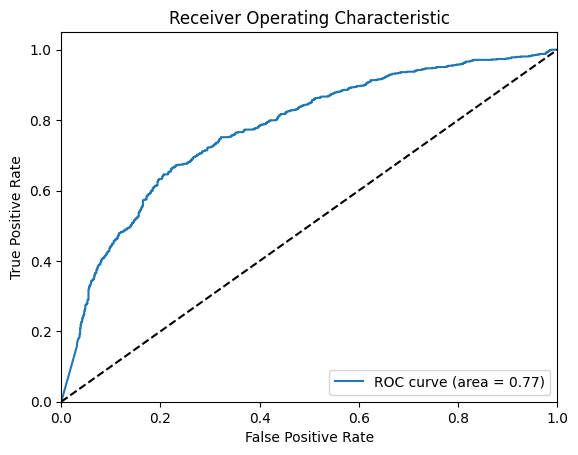

PR AUC: 0.7328060456194823


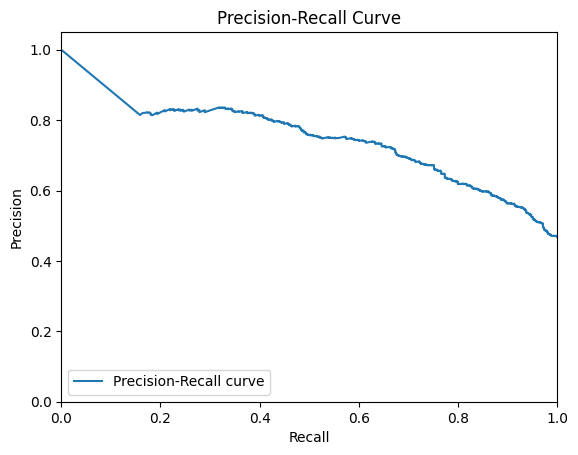

 38%|███▊      | 5/13 [00:32<00:44,  5.61s/it]


Confusion Matrix:
 [[762 186]
 [ 92 741]]


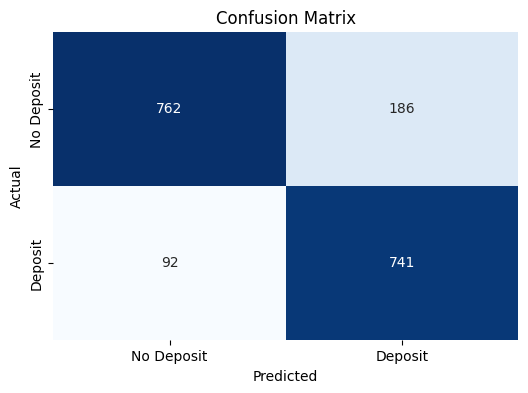


Classification Report:

              precision    recall  f1-score   support

  No Deposit       0.89      0.80      0.85       948
     Deposit       0.80      0.89      0.84       833

    accuracy                           0.84      1781
   macro avg       0.85      0.85      0.84      1781
weighted avg       0.85      0.84      0.84      1781

ROC-AUC: 0.9076022814188968


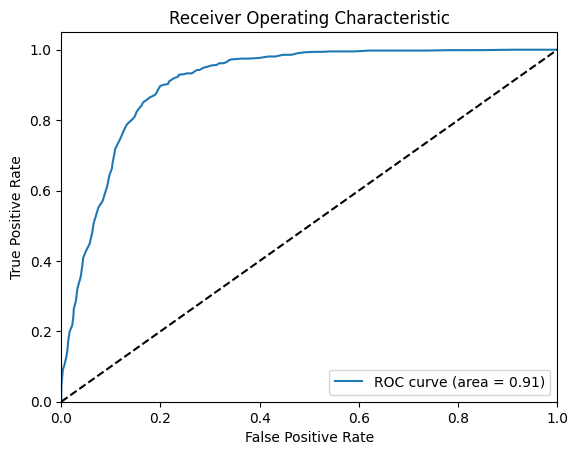

PR AUC: 0.8653987988861317


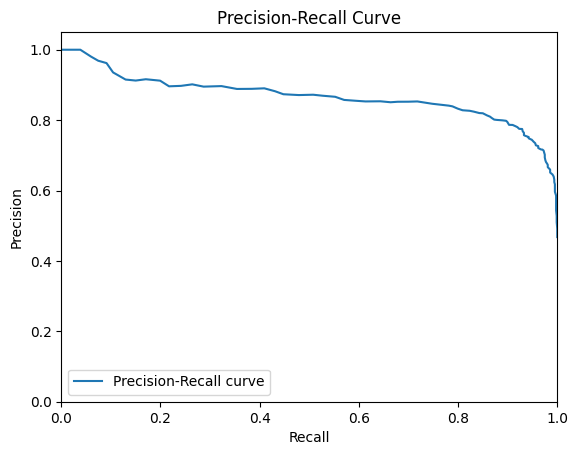

 46%|████▌     | 6/13 [00:35<00:31,  4.48s/it]


Confusion Matrix:
 [[781 167]
 [150 683]]


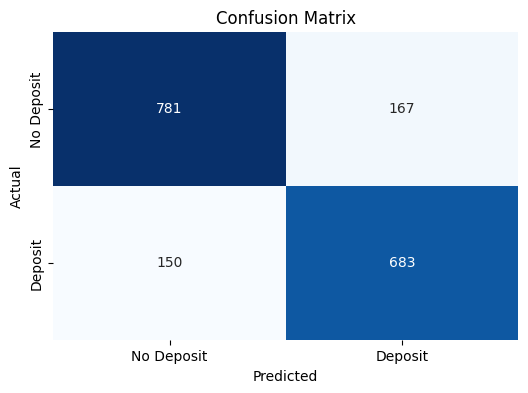


Classification Report:

              precision    recall  f1-score   support

  No Deposit       0.84      0.82      0.83       948
     Deposit       0.80      0.82      0.81       833

    accuracy                           0.82      1781
   macro avg       0.82      0.82      0.82      1781
weighted avg       0.82      0.82      0.82      1781

ROC-AUC: 0.8915965120225307


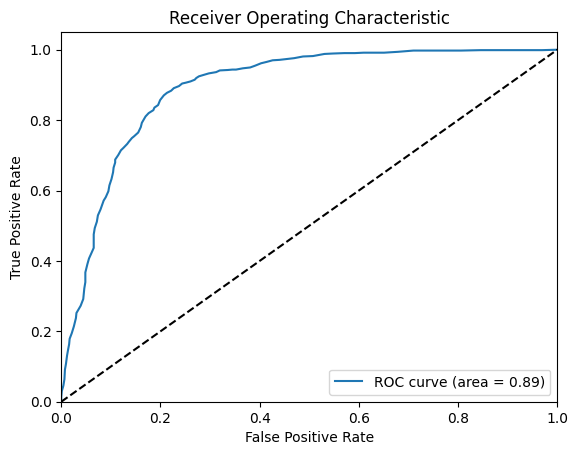

PR AUC: 0.8421237584169073


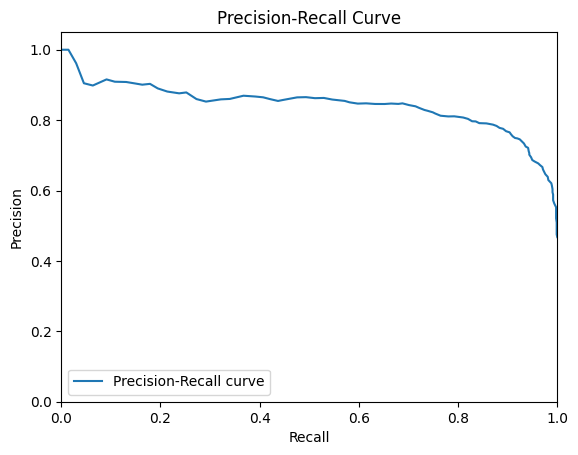

 54%|█████▍    | 7/13 [00:37<00:23,  3.95s/it]


Confusion Matrix:
 [[727 221]
 [170 663]]


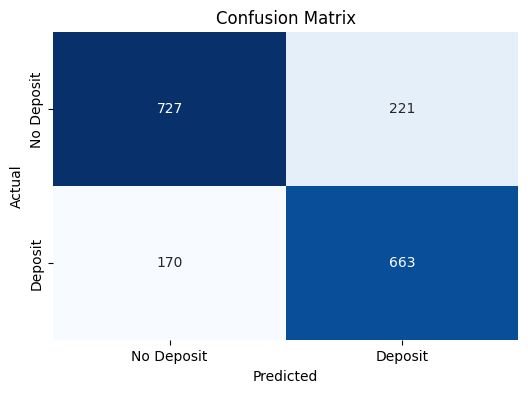


Classification Report:

              precision    recall  f1-score   support

  No Deposit       0.81      0.77      0.79       948
     Deposit       0.75      0.80      0.77       833

    accuracy                           0.78      1781
   macro avg       0.78      0.78      0.78      1781
weighted avg       0.78      0.78      0.78      1781

ROC-AUC: 0.8669771706150814


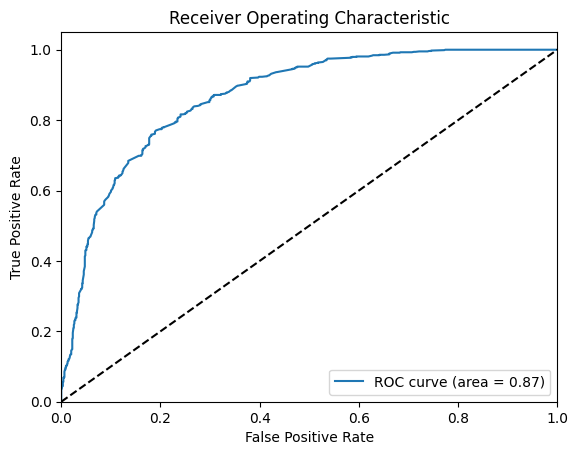

PR AUC: 0.8269454619936486


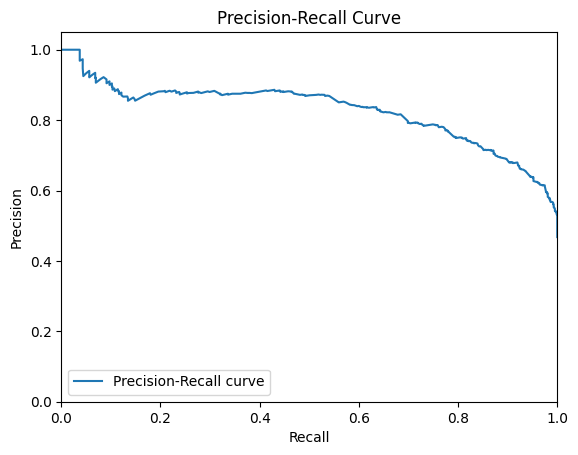

 62%|██████▏   | 8/13 [00:38<00:15,  3.02s/it]


Confusion Matrix:
 [[763 185]
 [118 715]]


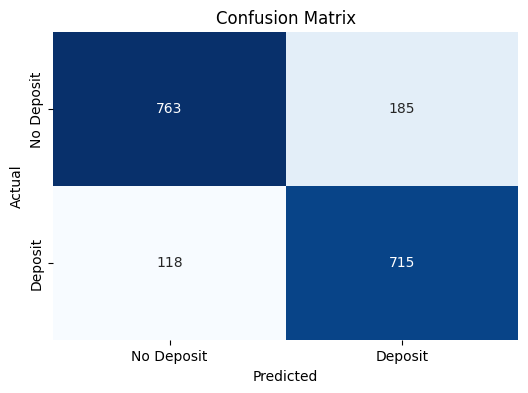


Classification Report:

              precision    recall  f1-score   support

  No Deposit       0.87      0.80      0.83       948
     Deposit       0.79      0.86      0.83       833

    accuracy                           0.83      1781
   macro avg       0.83      0.83      0.83      1781
weighted avg       0.83      0.83      0.83      1781

ROC-AUC: 0.9065284341584735


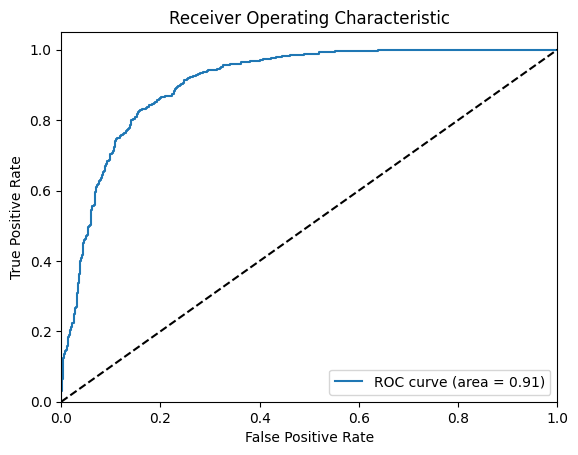

PR AUC: 0.8693890456486695


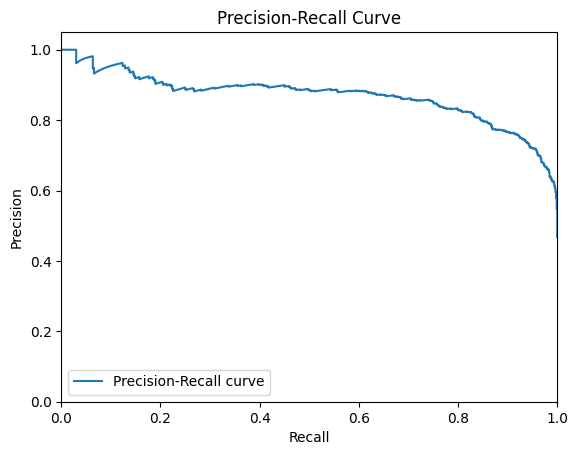

 69%|██████▉   | 9/13 [00:41<00:10,  2.74s/it]


Confusion Matrix:
 [[770 178]
 [100 733]]


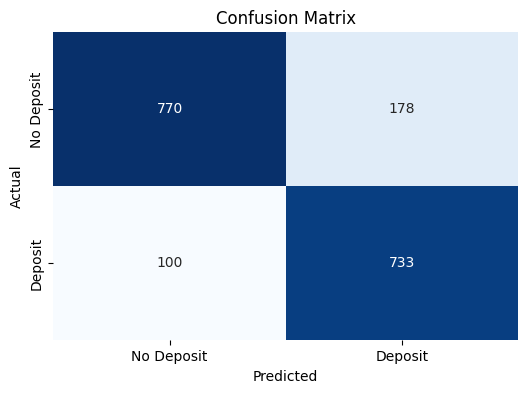


Classification Report:

              precision    recall  f1-score   support

  No Deposit       0.89      0.81      0.85       948
     Deposit       0.80      0.88      0.84       833

    accuracy                           0.84      1781
   macro avg       0.84      0.85      0.84      1781
weighted avg       0.85      0.84      0.84      1781

ROC-AUC: 0.9198122286889439


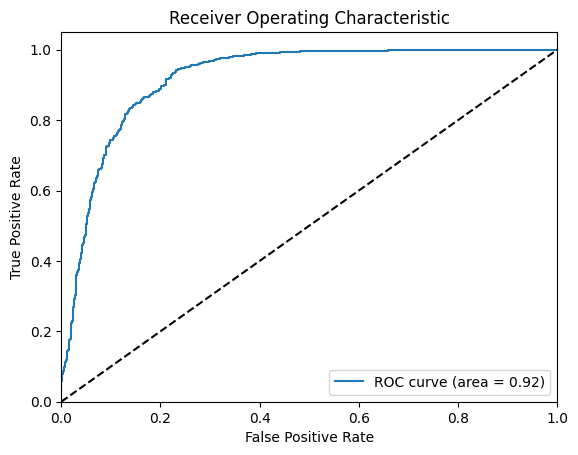

PR AUC: 0.8811488414880932


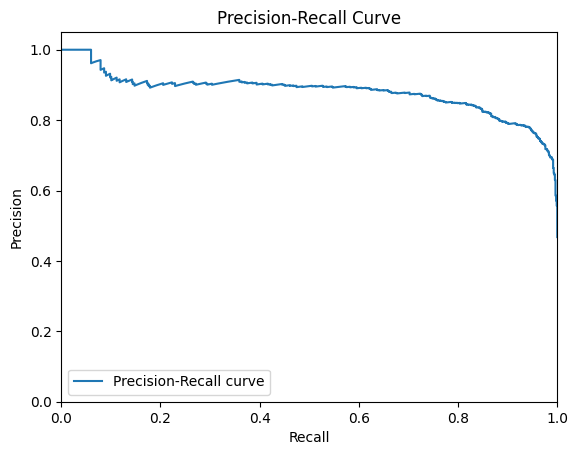

 77%|███████▋  | 10/13 [00:42<00:06,  2.31s/it]/usr/local/lib/python3.13/dist-packages/xgboost/training.py:200: UserWarning:

[16:31:29] WARNING: /__w/xgboost/xgboost/src/learner.cc:794: 
Parameters: { "use_label_encoder" } are not used.





Confusion Matrix:
 [[777 171]
 [105 728]]


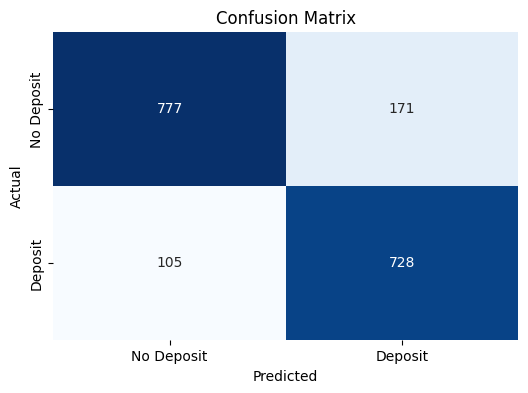


Classification Report:

              precision    recall  f1-score   support

  No Deposit       0.88      0.82      0.85       948
     Deposit       0.81      0.87      0.84       833

    accuracy                           0.85      1781
   macro avg       0.85      0.85      0.84      1781
weighted avg       0.85      0.85      0.85      1781

ROC-AUC: 0.9165906869076744


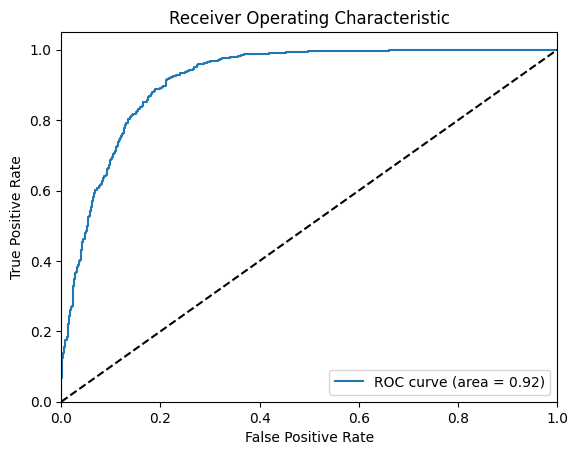

PR AUC: 0.8852746592282843


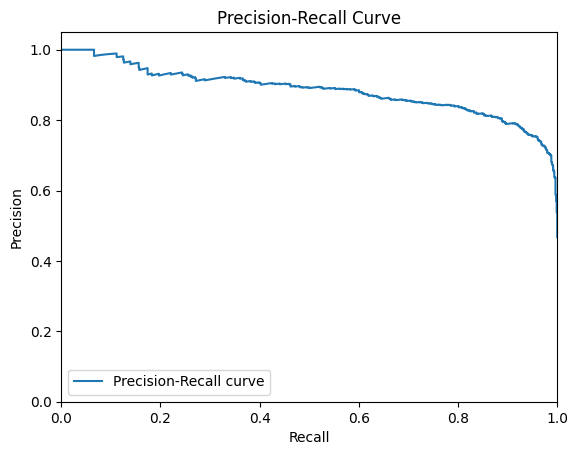

 85%|████████▍ | 11/13 [00:43<00:03,  1.85s/it]


Confusion Matrix:
 [[785 163]
 [ 88 745]]


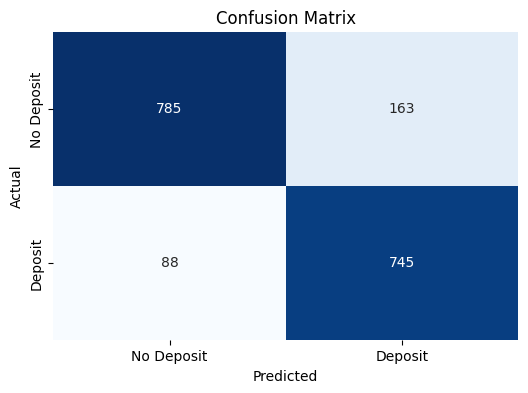


Classification Report:

              precision    recall  f1-score   support

  No Deposit       0.90      0.83      0.86       948
     Deposit       0.82      0.89      0.86       833

    accuracy                           0.86      1781
   macro avg       0.86      0.86      0.86      1781
weighted avg       0.86      0.86      0.86      1781

ROC-AUC: 0.925833624589076


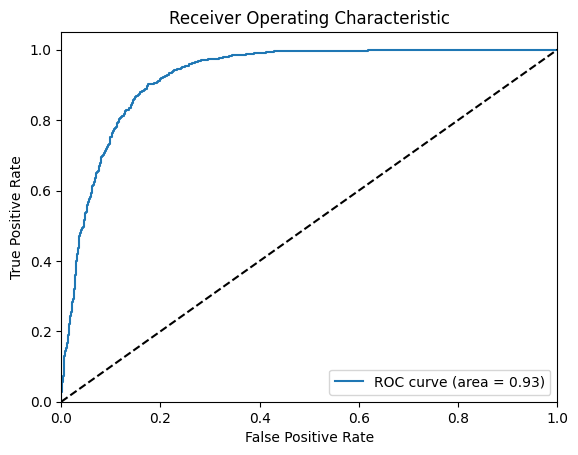

PR AUC: 0.889693432106243


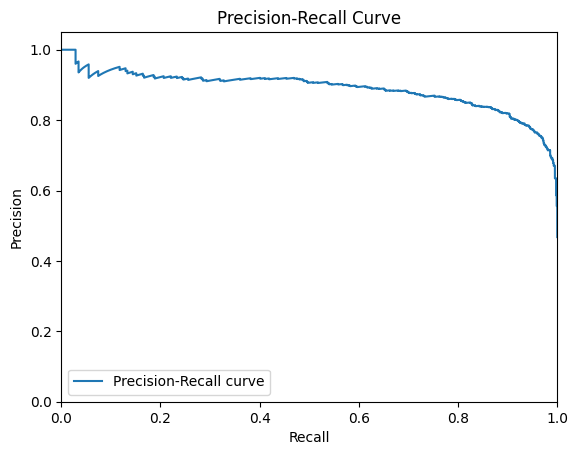

 92%|█████████▏| 12/13 [00:48<00:02,  2.79s/it]

[LightGBM] [Info] Number of positive: 3397, number of negative: 3725
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.002096 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 1009
[LightGBM] [Info] Number of data points in the train set: 7122, number of used features: 51
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.476973 -> initscore=-0.092174
[LightGBM] [Info] Start training from score -0.092174

Confusion Matrix:
 [[765 183]
 [ 92 741]]


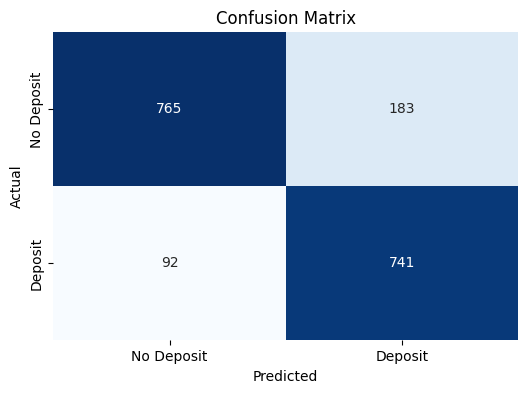


Classification Report:

              precision    recall  f1-score   support

  No Deposit       0.89      0.81      0.85       948
     Deposit       0.80      0.89      0.84       833

    accuracy                           0.85      1781
   macro avg       0.85      0.85      0.85      1781
weighted avg       0.85      0.85      0.85      1781

ROC-AUC: 0.9213216932342557


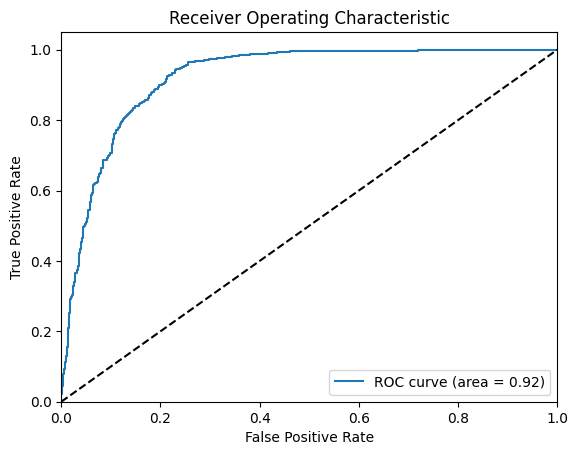

PR AUC: 0.8835483414769589


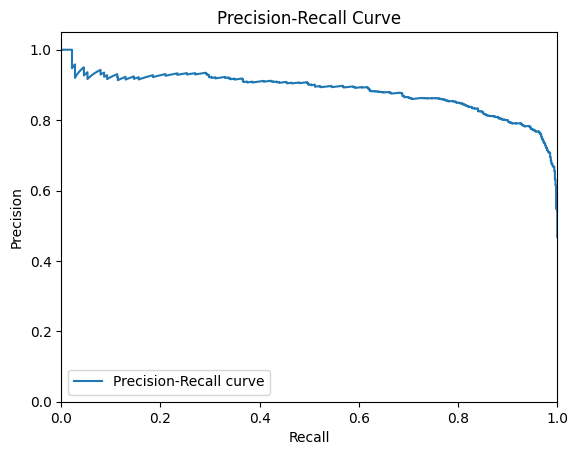

100%|██████████| 13/13 [00:49<00:00,  3.78s/it]


In [144]:
results = {}
# y_train and y_test are already mapped to 0 and 1 in the previous execution,
# but let's make sure we handle it safely if re-run.
if y_train.dtype == 'object':
    y_train = y_train.map({'no': 0, 'yes': 1})
if y_test.dtype == 'object':
    y_test = y_test.map({'no': 0, 'yes': 1})

for name, model in tqdm(models.items()):
    model.fit(x_train, y_train)

    train_pred = model.predict(x_train)
    test_pred  = model.predict(x_test)

    cm = confusion_matrix(y_test, test_pred)
    print("\nConfusion Matrix:\n", cm)

    plt.figure(figsize=(6,4))
    sns.heatmap(cm,annot=True,fmt="d",cmap='Blues',cbar=False,
                xticklabels=['No Deposit','Deposit']
                ,yticklabels=['No Deposit','Deposit'])
    plt.ylabel('Actual')
    plt.xlabel('Predicted')
    plt.title('Confusion Matrix')
    plt.show()

    # Full classification report
    print("\nClassification Report:\n")
    print(classification_report(y_test, test_pred,target_names=['No Deposit','Deposit'],zero_division=0))

    y_pred_prob = model.predict_proba(x_test)[:, 1]
    roc_auc = roc_auc_score(y_test, y_pred_prob)
    print("ROC-AUC:", roc_auc)

    # ROC curve (changed pos_label to 1)
    fpr, tpr, roc_thresholds = roc_curve(y_test, y_pred_prob, pos_label=1)
    plt.figure()
    plt.plot(fpr, tpr, label='ROC curve (area = {:.2f})'.format(roc_auc))
    plt.plot([0, 1], [0, 1], 'k--')
    plt.xlim([0.0, 1.0])
    plt.ylim([0.0, 1.05])
    plt.xlabel('False Positive Rate')
    plt.ylabel('True Positive Rate')
    plt.title('Receiver Operating Characteristic')
    plt.legend(loc="lower right")
    plt.show()

    pr_auc = average_precision_score(y_test, y_pred_prob, pos_label=1)
    print("PR AUC:", pr_auc)

    # Precision-Recall curve (changed pos_label to 1)
    precision_vals, recall_vals, pr_thresholds = precision_recall_curve(y_test, y_pred_prob, pos_label=1)
    plt.figure()
    plt.plot(recall_vals, precision_vals, label='Precision-Recall curve')
    plt.xlim([0.0, 1.0])
    plt.ylim([0.0, 1.05])
    plt.xlabel('Recall')
    plt.ylabel('Precision')
    plt.title('Precision-Recall Curve')
    plt.legend(loc="lower left")
    plt.show()

    results[name] = {
        "Train Accuracy": accuracy_score(y_train, train_pred),
        "Test Accuracy": accuracy_score(y_test, test_pred),
        "Train Precision": precision_score(y_train, train_pred, pos_label=1),
        "Test Precision": precision_score(y_test, test_pred, pos_label=1),
        "Train Recall": recall_score(y_train, train_pred, pos_label=1),
        "Test Recall": recall_score(y_test, test_pred, pos_label=1),
        "Train F1 Score": f1_score(y_train, train_pred, pos_label=1),
        "Test F1 Score": f1_score(y_test, test_pred, pos_label=1),
        "Train Balanced Accuracy": balanced_accuracy_score(y_train, train_pred),
        "Test Balanced Accuracy": balanced_accuracy_score(y_test, test_pred),
        "ROC-AUC": roc_auc,
        "PR AUC": pr_auc
    }

# **Voting** **Classification**

/usr/local/lib/python3.13/dist-packages/xgboost/training.py:200: UserWarning:

[16:32:17] WARNING: /__w/xgboost/xgboost/src/learner.cc:794: 
Parameters: { "use_label_encoder" } are not used.





Confusion Matrix:
 [[804 144]
 [153 680]]


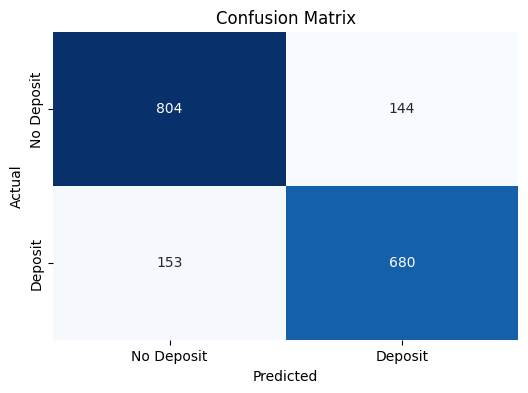


Classification Report:

              precision    recall  f1-score   support

  No Deposit       0.84      0.85      0.84       948
     Deposit       0.83      0.82      0.82       833

    accuracy                           0.83      1781
   macro avg       0.83      0.83      0.83      1781
weighted avg       0.83      0.83      0.83      1781

ROC-AUC: 0.9050227686011113


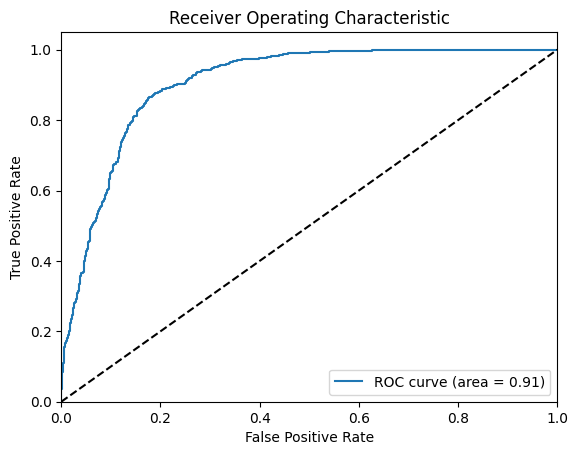

PR AUC: 0.8670530174029393


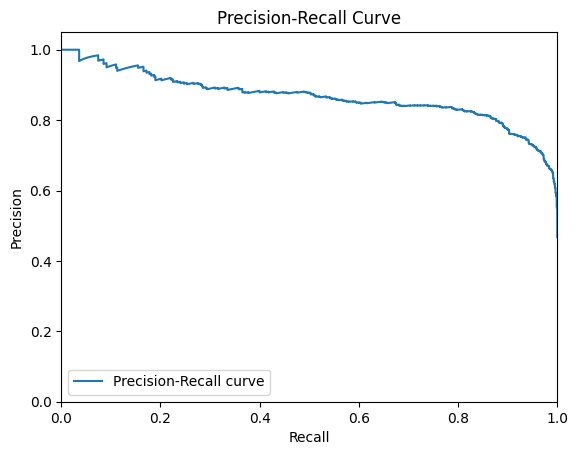

In [145]:
voting_model = VotingClassifier(
    estimators=[
        ("lr", models["Logistic Regression"]),
        ("rf", models["Random Forest"]),
        ("nb", models["Naive Bayes"]),
        ("xgb", models["XGBoost"]),
    ],
    voting="soft" # voting='hard' / voting='soft', weights=[2, 1, 2,1]
)

voting_model.fit(x_train, y_train)
voting_train_pred = voting_model.predict(x_train)
voting_test_pred = voting_model.predict(x_test)

cm = confusion_matrix(y_test, voting_test_pred)
print("\nConfusion Matrix:\n", cm)

plt.figure(figsize=(6,4))
sns.heatmap(cm,annot=True,fmt="d",cmap='Blues',cbar=False,
             xticklabels=['No Deposit','Deposit']
            ,yticklabels=['No Deposit','Deposit'])
plt.ylabel('Actual')
plt.xlabel('Predicted')
plt.title('Confusion Matrix')
plt.show()

# Full classification report
print("\nClassification Report:\n")
print(classification_report(y_test, voting_test_pred,target_names=['No Deposit','Deposit'],zero_division=0))

y_pred_prob = voting_model.predict_proba(x_test)[:, 1]
roc_auc = roc_auc_score(y_test, y_pred_prob)
print("ROC-AUC:", roc_auc)

# ROC curve (changed pos_label to 1)
fpr, tpr, roc_thresholds = roc_curve(y_test, y_pred_prob, pos_label=1)
plt.figure()
plt.plot(fpr, tpr, label='ROC curve (area = {:.2f})'.format(roc_auc))
plt.plot([0, 1], [0, 1], 'k--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic')
plt.legend(loc="lower right")
plt.show()

pr_auc = average_precision_score(y_test, y_pred_prob, pos_label=1)
print("PR AUC:", pr_auc)

# Precision-Recall curve (changed pos_label to 1)
precision_vals, recall_vals, pr_thresholds = precision_recall_curve(y_test, y_pred_prob, pos_label=1)
plt.figure()
plt.plot(recall_vals, precision_vals, label='Precision-Recall curve')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-Recall Curve')
plt.legend(loc="lower left")
plt.show()

results["Voting Classifier"] = {
    "Train Accuracy": accuracy_score(y_train, voting_train_pred),
    "Test Accuracy": accuracy_score(y_test, voting_test_pred),
    "Train Precision": precision_score(y_train, voting_train_pred, pos_label=1),
    "Test Precision": precision_score(y_test, voting_test_pred, pos_label=1),
    "Train Recall": recall_score(y_train, voting_train_pred, pos_label=1),
    "Test Recall": recall_score(y_test, voting_test_pred, pos_label=1),
    "Train F1 Score": f1_score(y_train, voting_train_pred, pos_label=1),
    "Test F1 Score": f1_score(y_test, voting_test_pred, pos_label=1),
    "Train Balanced Accuracy": balanced_accuracy_score(y_train, voting_train_pred),
    "Test Balanced Accuracy": balanced_accuracy_score(y_test, voting_test_pred),
    "ROC-AUC": roc_auc,
    "PR AUC": pr_auc
}

# **Stacking** **Classifier**

/usr/local/lib/python3.13/dist-packages/xgboost/training.py:200: UserWarning:

[16:32:33] WARNING: /__w/xgboost/xgboost/src/learner.cc:794: 
Parameters: { "use_label_encoder" } are not used.





Confusion Matrix:
 [[753 195]
 [ 77 756]]


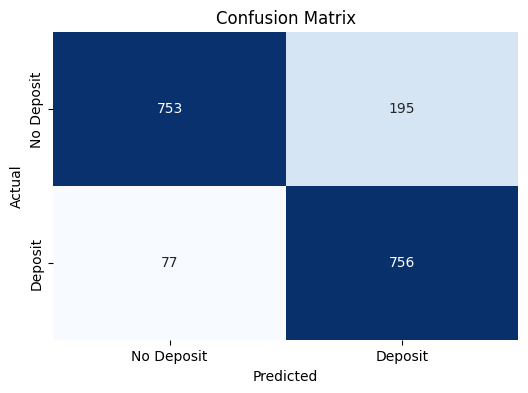


Classification Report:

              precision    recall  f1-score   support

  No Deposit       0.91      0.79      0.85       948
     Deposit       0.79      0.91      0.85       833

    accuracy                           0.85      1781
   macro avg       0.85      0.85      0.85      1781
weighted avg       0.85      0.85      0.85      1781

ROC-AUC: 0.9031270736142558


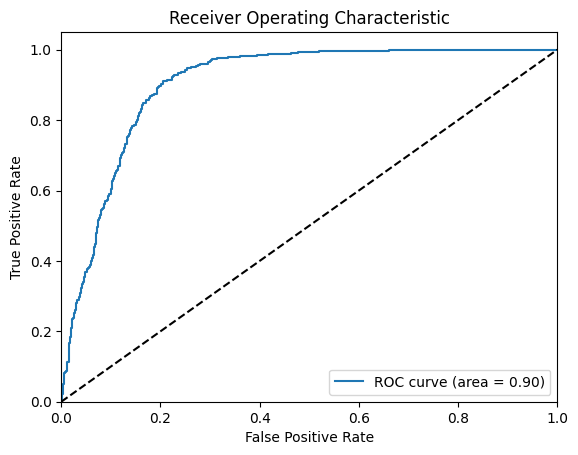

PR AUC: 0.8470999480723146


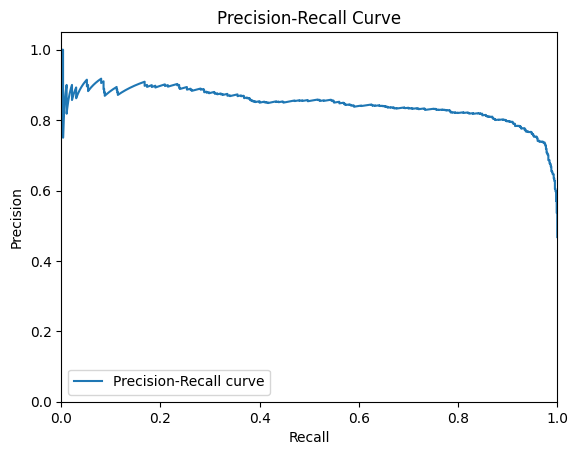

In [146]:
stack_auto = StackingClassifier(
    estimators=[
        ("lr", models["Logistic Regression"]),
        ("rf", models["Random Forest"]),
        ("nb", models["Naive Bayes"]),
        ("lgbm", models["LightGBM"]),
    ],
    final_estimator=XGBClassifier(eval_metric='logloss', random_state=1, use_label_encoder=False),
    stack_method="predict_proba",   # best for classification usually
    n_jobs=-1
)

# Train
stack_auto.fit(x_train, y_train)

# Predictions
stack_auto_train_pred = stack_auto.predict(x_train)
stack_auto_test_pred  = stack_auto.predict(x_test)

cm = confusion_matrix(y_test, stack_auto_test_pred)
print("\nConfusion Matrix:\n", cm)

plt.figure(figsize=(6,4))
sns.heatmap(cm,annot=True,fmt="d",cmap='Blues',cbar=False,
             xticklabels=['No Deposit','Deposit']
            ,yticklabels=['No Deposit','Deposit'])
plt.ylabel('Actual')
plt.xlabel('Predicted')
plt.title('Confusion Matrix')
plt.show()

# Full classification report
print("\nClassification Report:\n")
print(classification_report(y_test, stack_auto_test_pred,target_names=['No Deposit','Deposit'],zero_division=0))

y_pred_prob = stack_auto.predict_proba(x_test)[:, 1]
roc_auc = roc_auc_score(y_test, y_pred_prob)
print("ROC-AUC:", roc_auc)

# ROC curve (changed pos_label to 1)
fpr, tpr, roc_thresholds = roc_curve(y_test, y_pred_prob, pos_label=1)
plt.figure()
plt.plot(fpr, tpr, label='ROC curve (area = {:.2f})'.format(roc_auc))
plt.plot([0, 1], [0, 1], 'k--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic')
plt.legend(loc="lower right")
plt.show()

pr_auc = average_precision_score(y_test, y_pred_prob, pos_label=1)
print("PR AUC:", pr_auc)

# Precision-Recall curve (changed pos_label to 1)
precision_vals, recall_vals, pr_thresholds = precision_recall_curve(y_test, y_pred_prob, pos_label=1)
plt.figure()
plt.plot(recall_vals, precision_vals, label='Precision-Recall curve')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-Recall Curve')
plt.legend(loc="lower left")
plt.show()

results["Stacking Classifier "] = {
    "Train Accuracy": accuracy_score(y_train, stack_auto_train_pred),
    "Test Accuracy": accuracy_score(y_test, stack_auto_test_pred),
    "Train Precision": precision_score(y_train, stack_auto_train_pred, pos_label=1),
    "Test Precision": precision_score(y_test, stack_auto_test_pred, pos_label=1),
    "Train Recall": recall_score(y_train, stack_auto_train_pred, pos_label=1),
    "Test Recall": recall_score(y_test, stack_auto_test_pred, pos_label=1),
    "Train F1 Score": f1_score(y_train, stack_auto_train_pred, pos_label=1),
    "Test F1 Score": f1_score(y_test, stack_auto_test_pred, pos_label=1),
    "Train Balanced Accuracy": balanced_accuracy_score(y_train, stack_auto_train_pred),
    "Test Balanced Accuracy": balanced_accuracy_score(y_test, stack_auto_test_pred),
    "ROC-AUC": roc_auc,
    "PR AUC": pr_auc
}

In [147]:
results_df = pd.DataFrame(results).T
results_df = results_df.sort_values(by="Test F1 Score", ascending=False)

In [148]:
results_df

,Train Accuracy,Test Accuracy,Train Precision,Test Precision,Train Recall,Test Recall,Train F1 Score,Test F1 Score,Train Balanced Accuracy,Test Balanced Accuracy,ROC-AUC,PR AUC
CatBoost,0.918001,0.859068,0.896532,0.820485,0.936120,0.894358,0.915899,0.855830,0.918798,0.861208,0.925834,0.889693
Stacking Classifier,0.921090,0.847277,0.890388,0.794953,0.951722,0.907563,0.920034,0.847534,0.922438,0.850933,0.903127,0.847100
LightGBM,0.918703,0.845592,0.889442,0.801948,0.947306,0.889556,0.917463,0.843483,0.919962,0.848259,0.921322,0.883548
Random Forest,1.000000,0.843908,1.000000,0.799353,1.000000,0.889556,1.000000,0.842045,1.000000,0.846677,0.907602,0.865399
XGBoost,0.967846,0.845031,0.960198,0.809789,0.972917,0.873950,0.966516,0.840647,0.968069,0.846785,0.916591,0.885275
Hist Gradient Boosting,0.917018,0.843908,0.889506,0.804610,0.943185,0.879952,0.915559,0.840596,0.918170,0.846094,0.919812,0.881149
SVC,0.879669,0.842785,0.852778,0.800871,0.903739,0.883553,0.877519,0.840183,0.880728,0.845258,0.910654,0.868508
Gradient Boosting,0.861415,0.829871,0.840588,0.794444,0.875478,0.858343,0.857678,0.825159,0.862034,0.831598,0.906528,0.869389
Voting Classifier,0.921511,0.833240,0.924596,0.825243,0.909626,0.816327,0.917050,0.820760,0.920988,0.832214,0.905023,0.867053
Logistic Regression,0.828559,0.827625,0.834563,0.823096,0.798940,0.804322,0.816363,0.813600,0.827255,0.826211,0.892514,0.855782


<Axes: >

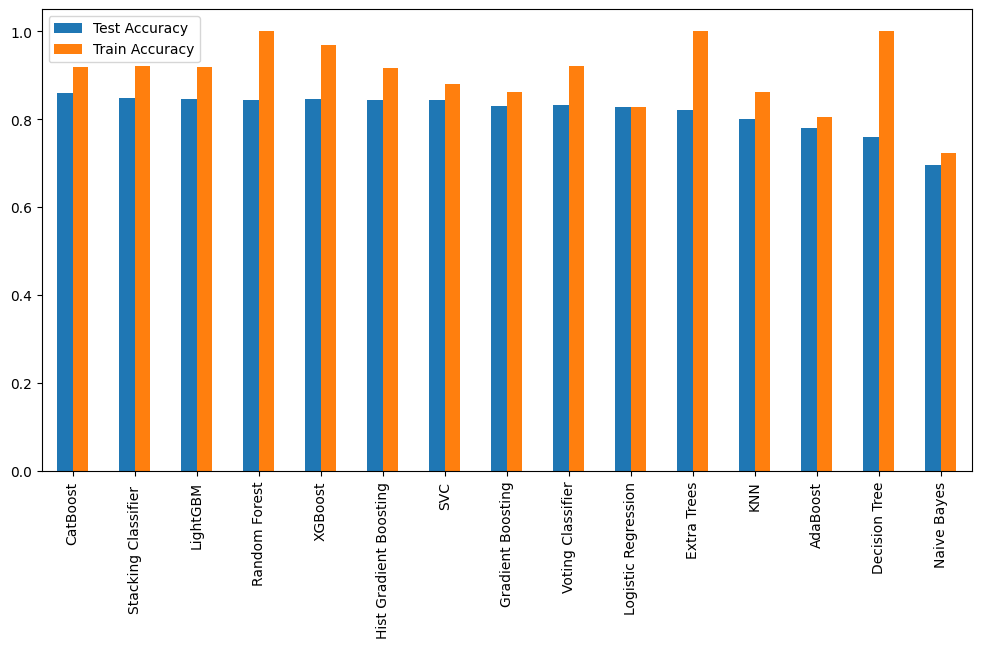

In [149]:
results_df[["Test Accuracy", "Train Accuracy"]].plot.bar(figsize=(12,6))

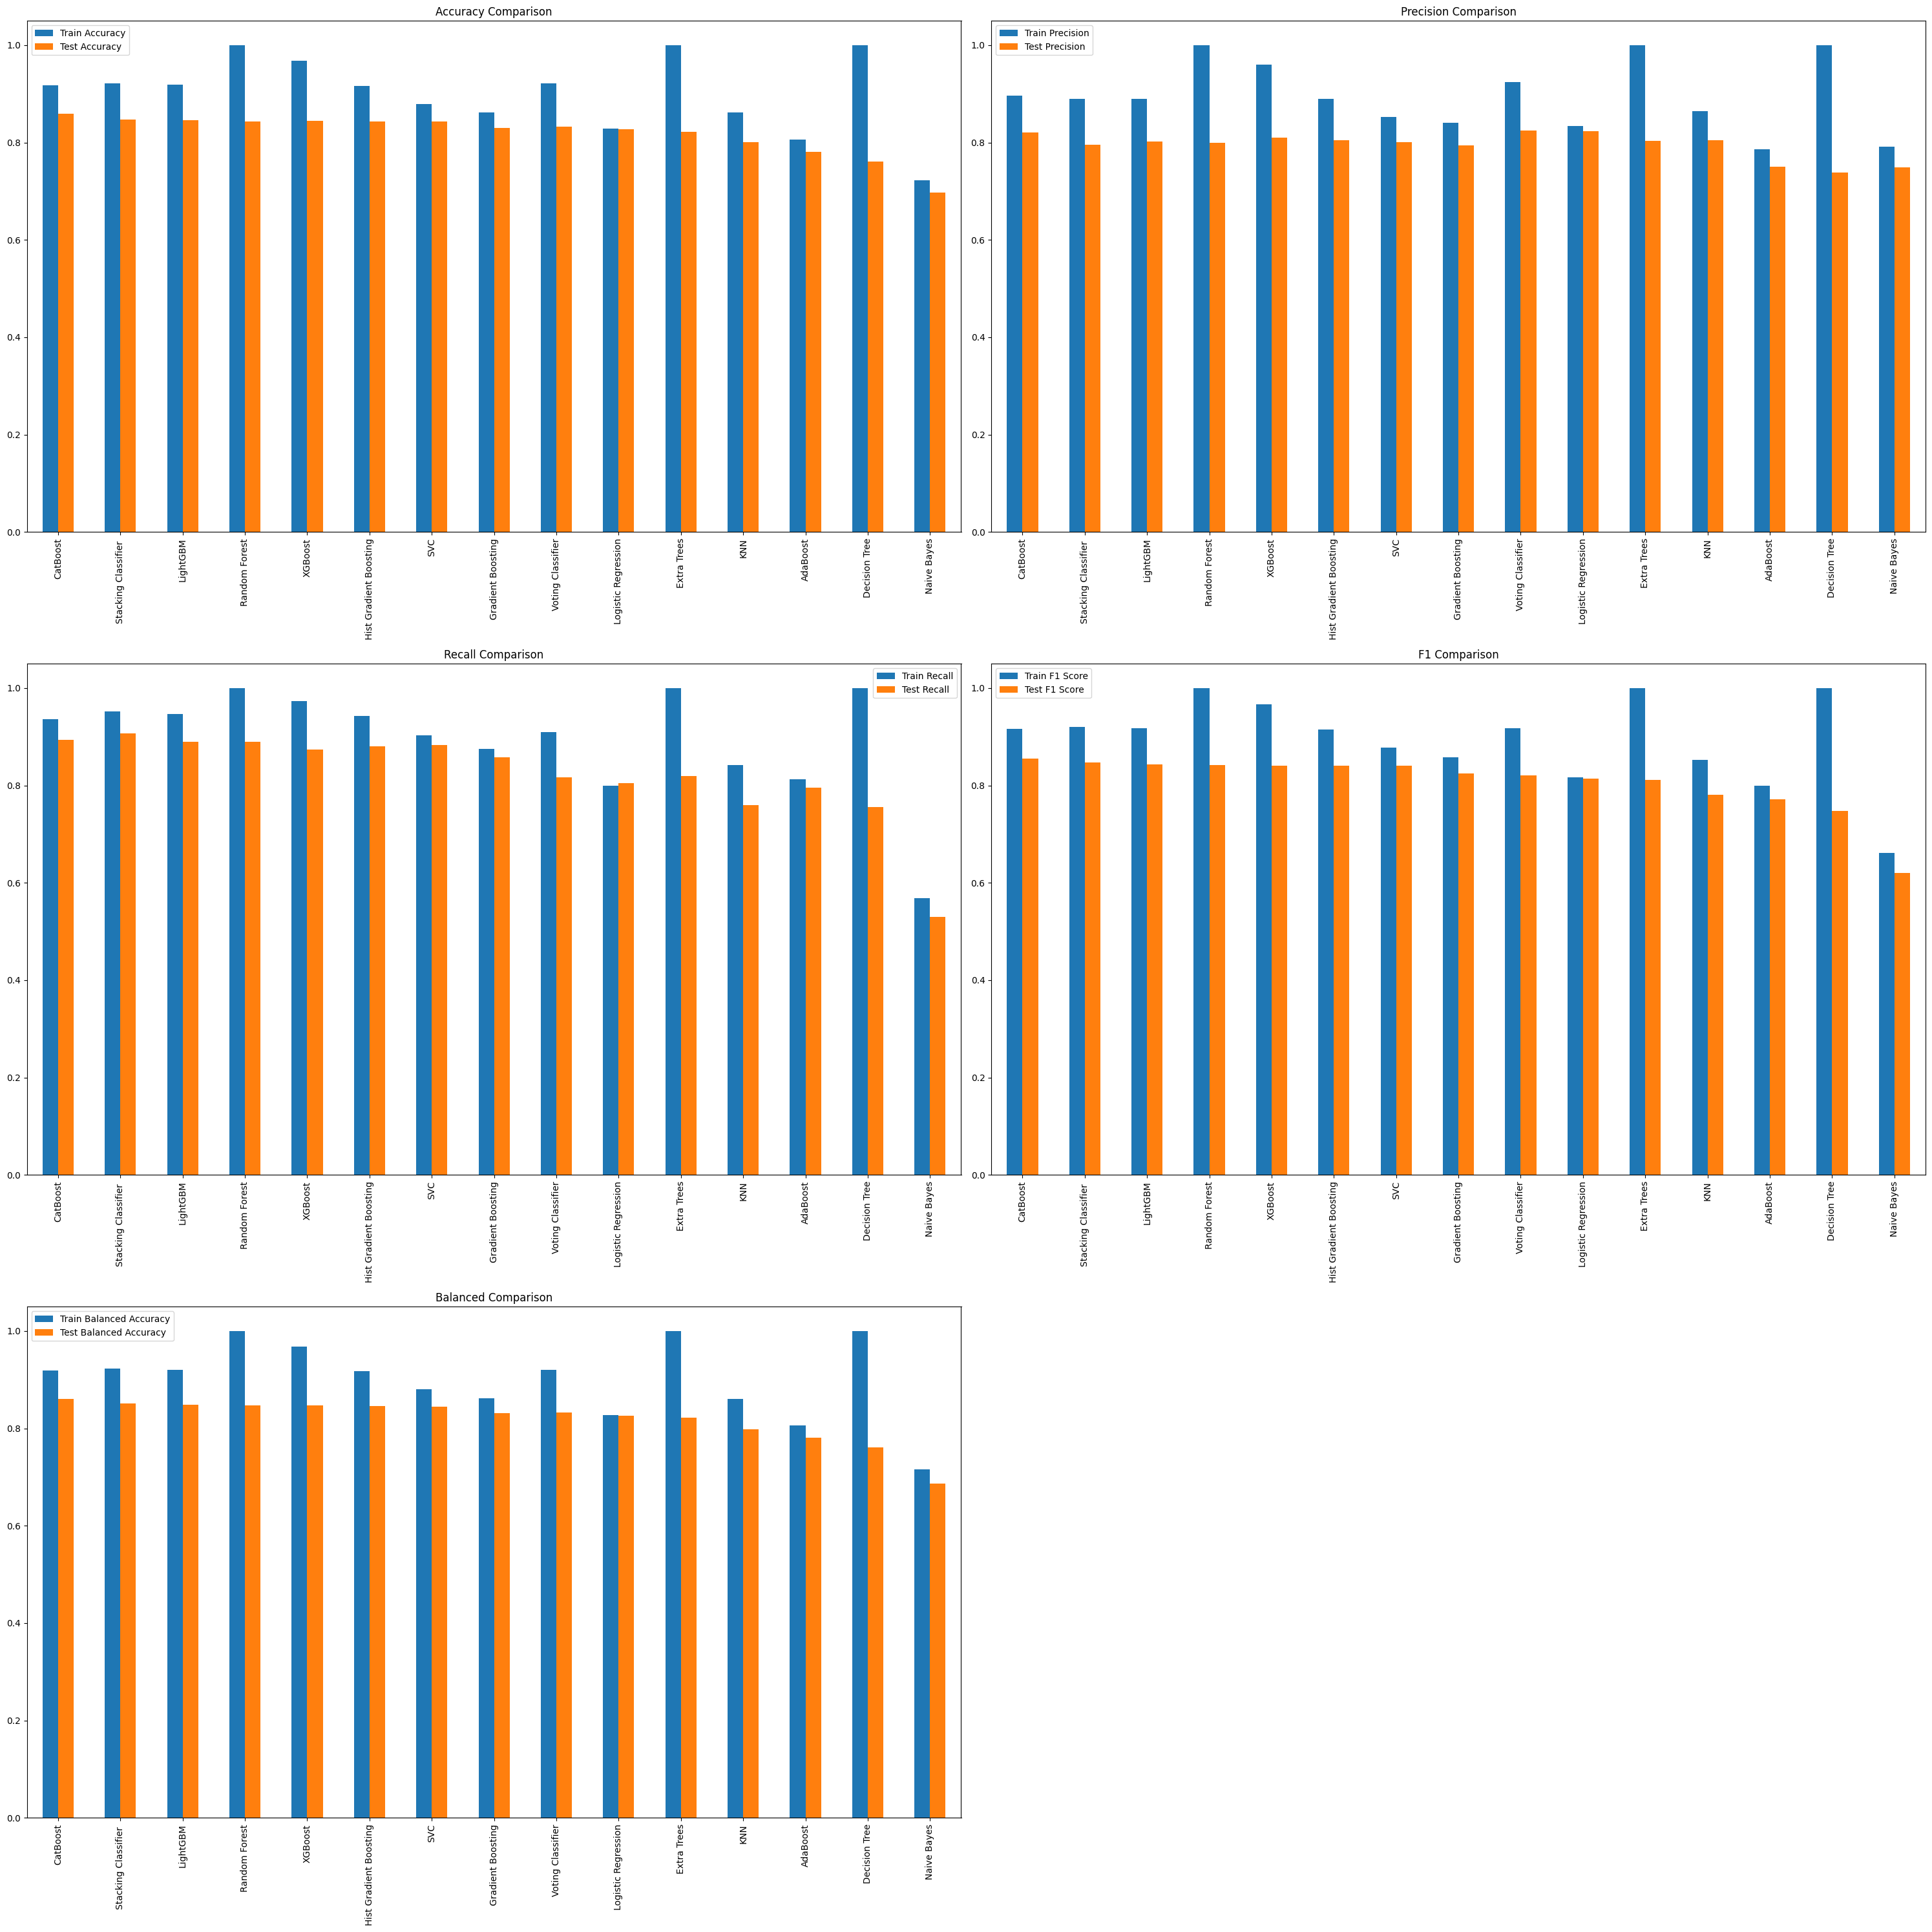

In [150]:
cols = [
    ['Train Accuracy', 'Test Accuracy'],
    ['Train Precision', 'Test Precision'],
    ['Train Recall', 'Test Recall'],
    ['Train F1 Score', 'Test F1 Score'],
    ["Train Balanced Accuracy", "Test Balanced Accuracy"]
]

plt.figure(figsize=(30,30))

for i, col in enumerate(cols):
    ax = plt.subplot(3, 2, i+1)
    results_df[col].plot.bar(ax=ax)
    ax.set_title(col[0].split(" ")[1] + ' Comparison')

plt.tight_layout()
plt.show()